In [1]:
import pandas as pd
import numpy as np
pd.set_option("display.max_column", 8) # 设置最大显示列数

data = pd.read_csv(r'creditcard.csv')
data.head()

,Time,V1,V2,V3,...,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,...,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,...,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,...,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,...,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,...,0.219422,0.215153,69.99,0


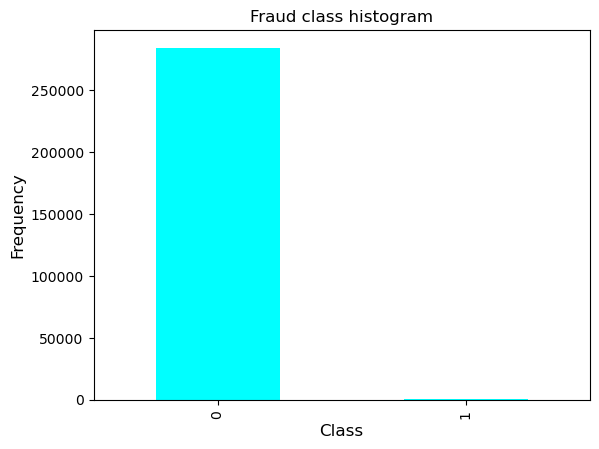

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

# 查看目标变量的分布
data['Class'].value_counts().plot(kind="bar", colormap="cool")
plt.title("Fraud class histogram", fontsize=12)
plt.xlabel("Class", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.show()

In [3]:
data['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

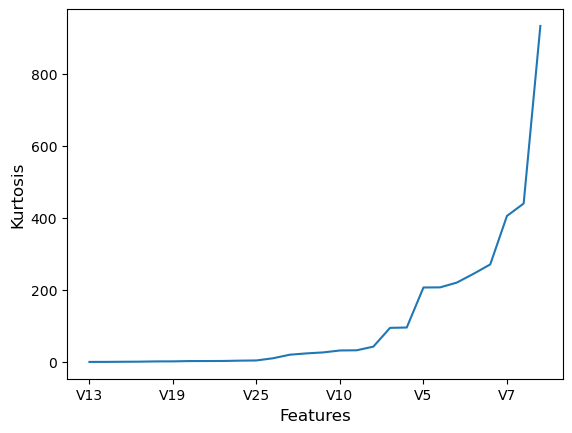

In [4]:
# 计算自变量峰度并按峰度排序
train = data.loc[:, 'V1':'V28'].copy()
ax = train.kurtosis().sort_values().plot()
ax.set_xlabel("Features", fontsize=12)
ax.set_ylabel("Kurtosis", fontsize=12)
plt.show(ax)

### 孤立森林

孤立森林会自动根据峰度对变量进行采样。

用ARI做评估标准

In [5]:
"""
1使用孤立森林识别异常值
"""
"""
主要的参数是contamination,一般情况下为坏样本比例的5-20倍
比如坏样本492,而我们要求的精确度不低于5%，则该参数为(425+67)*20/284807=0.0345
"""
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score

rng = np.random.RandomState(42)

iso = IsolationForest( 
    contamination=0.02,  # 异常点占比
    n_estimators=100,    # 子树数量
    max_samples=0.6,     # 每棵子树用到的样本量
    max_features=0.6,    # 建立子树时用到的属性数量
    random_state=rng,    # 便于复现结果而设置的随机种子
    n_jobs=-1
)
# 训练、预测
iso_outlier = iso.fit_predict(train)

# 评估
print("CrossTable: \n", pd.crosstab(data['Class'], iso_outlier))
print("ARI: ", adjusted_rand_score(data['Class'], iso_outlier))

CrossTable: 
 col_0    -1       1
Class              
0      5293  279022
1       404      88
ARI:  0.12531258644539264


交叉验证随机搜索参数

In [6]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

n_iter = 10
param_distributions = {
    "contamination": uniform(0.015, 0.01),# 异常点占比
    "n_estimators": randint(80, 121),     # 子树数量
    "max_samples": uniform(0.5, 0.2),     # 建立子树的样本量
    "max_features": uniform(0.5, 0.2),    # 建立子树的属性数量
}
iso = IsolationForest(random_state=rng)
iso_cv = RandomizedSearchCV(
    estimator=iso, 
    param_distributions=param_distributions,
    scoring='adjusted_rand_score',
    cv=3,
    n_iter=n_iter,
    n_jobs=-1
)

iso_cv.fit(train, data['Class'])  # 交叉验证需要输入`y_true`
print("Best_params: ", iso_cv.best_params_)
print("Best_score: ", iso_cv.best_score_)

Best_params:  {'contamination': 0.015504329474940175, 'max_features': 0.5302519421647717, 'max_samples': 0.6381676661453477, 'n_estimators': 85}
Best_score:  0.15064925276036764


In [7]:
best_iso = iso_cv.best_estimator_
best_iso_outlier = best_iso.predict(train)
print("CrossTable: \n", pd.crosstab(data['Class'], best_iso_outlier))
print("-" * 50)
print("ARI: ", adjusted_rand_score(data['Class'], best_iso_outlier))

CrossTable: 
 col_0    -1       1
Class              
0      4018  280297
1       398      94
--------------------------------------------------
ARI:  0.1572274493333505


保存与读取

In [8]:
# import pickle as pickle

# #保存模型
# with open(r'M_IsolationForest.model', 'wb') as f:
#     pickle.dump(best_iso, f)


# #加载模型
# with open(r'M_IsolationForest.model', 'rb') as f:
#     clf_load = pickle.load(f)

### Local Outlier Factor

In [9]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import adjusted_rand_score
import time

lof = LocalOutlierFactor(
    n_neighbors=500,     # k-距离中的k值
    contamination=0.02,  # 异常点占比
    novelty=True,       # 模型是否可用于predict
    n_jobs=-1           # 计算并行度
)
start = time.time()
lof.fit(train)
lof_outlier = lof.predict(train)
print(time.time() - start)
print("CrossTable: \n", pd.crosstab(data['Class'], lof_outlier))
print("ARI: ", adjusted_rand_score(data['Class'], lof_outlier))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


375.7357568740845
CrossTable: 
 col_0    -1       1
Class              
0      5248  279067
1       405      87
ARI:  0.1265758437351802


交叉验证随机参数搜索 （计算量大！！）

In [ ]:
# from sklearn.neighbors import LocalOutlierFactor
# from sklearn.model_selection import RandomizedSearchCV
# from scipy.stats import randint, uniform
# from sklearn.metrics import adjusted_rand_score
# import time


# n_iter = 2
# param_distributions = {
#     "n_neighbors": randint(100, 500),
#     "contamination": uniform(0.02, 0.04),
# }
# lof = LocalOutlierFactor(algorithm="kd_tree", novelty=True)
# lof_cv = RandomizedSearchCV(
#     estimator=lof, 
#     param_distributions=param_distributions,
#     scoring='adjusted_rand_score',
#     cv=3,
#     n_iter=n_iter,
#     n_jobs=-1,
# )

# start = time.time()
# lof_cv.fit(train, data['Class'])  # 交叉验证需要输入ground true

# print(time.time() - start)
# print("Best_params: ", lof_cv.best_params_)
# print("Best_score: ", lof_cv.best_score_)

In [ ]:
# best_lof = lof_cv.best_estimator_
# best_lof_outlier = best_lof.predict(train)

# print("CrossTable: \n", pd.crosstab(data['Class'], best_lof_outlier))
# print("ARI: ", adjusted_rand_score(data['Class'], best_lof_outlier))